In [1]:
from auxillaryFunctions import *
np.random.seed(0)

STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.1
GPeBias = -0.23


TS = 0.05
simScale = 4
k = 10
nSTN,nGPe,nIdk = simScale,3*simScale,0
nCTX,nMSN = 10*simScale, 30*simScale
CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe


STNDendriteMap = []
STNDendriteInfo = []

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nGPe)]
idkNeurons = [Neuron(i,"idk","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nIdk)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}

CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,0.015,0.2,TS)
STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,0.015,4,TS) #
GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,0.5,4,TS)
GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,0.025,4,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nGPe_GPe,0.02,0.2,TS)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}


simData,connectionToChannelMap = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

Total number of channels 1720


In [2]:
stimInfoSpikes = {}
syns = [i for i,n in enumerate(simData["name"]) if n == "AMPAR"] #"AMPAR" #GABA
#stimSynapse(stimInfoSpikes,syns,50,100,TS

runTime = 150
stimInfoCurrents = {} 

simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])

data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True,nSamples=None, useTQDM=True,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent","spikerOutput"])


  0%|          | 0/6000 [00:00<?, ?it/s]

  1%|          | 50/6000 [00:00<00:12, 494.37it/s]c:\Users\CathalMcLoughlin\Documents\GitHub\pythonCPPtesting.ipynb\auxillaryFunctions.py:50: RuntimeWarning: overflow encountered in exp
  return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))
100%|██████████| 6000/6000 [00:12<00:00, 484.11it/s]


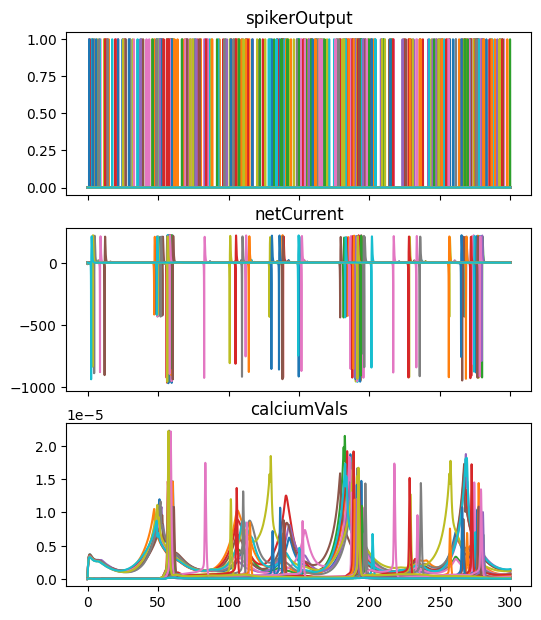

In [3]:
keysToPlot = ["spikerOutput","netCurrent","calciumVals","time"]
standardPlot({key:data[key] for key in keysToPlot})

C:\Users\CathalMcLoughlin\AppData\Local\Temp\ipykernel_9428\3986517046.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend();


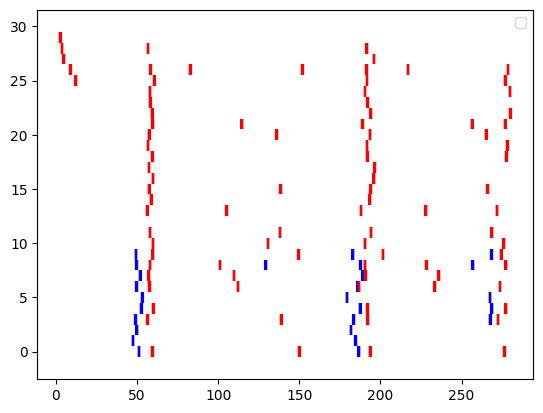

In [3]:
def getPopSpikeTrains(simDataPy,data):
    neuronToSpiker = {}
    for i,val in enumerate(simDataPy["spikerPreNeuron"]):
        if val not in neuronToSpiker.keys():
            neuronToSpiker[i] = int(val)

    neuronPopToSpiker = {}
    spikerToPop = {}

    for i,name in enumerate(simDataPy["neuronName"]):
        if name not in neuronPopToSpiker:
            neuronPopToSpiker[name] = []
        neuronPopToSpiker[name].append(i)
        spikerToPop[i] = name

    spikes = data["spikerOutput"][:,neuronPopToSpiker["GPe"][1]]
    nNeurons = simDataPy["nNeurons"]
    spikeTimes = [[] for i in range(nNeurons)]
    for timeInd,neurInd in zip(*np.where(data["spikerOutput"][:,0:nNeurons]==1)):
        spikeTimes[neurInd].append(float(data["time"][timeInd]))

    popSpikeTrains = {k:[] for k in neuronPopToSpiker.keys()}
    for i,trains in enumerate(spikeTimes):
        popSpikeTrains[spikerToPop[i]].append(trains)
    return popSpikeTrains

popSpikeTrains = getPopSpikeTrains(simDataPy,data)
fig,ax = plt.subplots(1,1)
ax.eventplot(popSpikeTrains["STN"],color="b");
ax.eventplot(popSpikeTrains["GPe"],color="r");
ax.legend();

In [4]:
simDataPy["spikeTrains"] #NOTE: I dont like this philosophy of this and it sholud be removed later. Keep state and recording data separate 


[[1020,
  1021,
  1022,
  1023,
  1024,
  1025,
  1026,
  1027,
  1028,
  3729,
  3730,
  3731,
  3732,
  3733,
  3734,
  3735,
  3736,
  3737,
  3738],
 [945,
  946,
  947,
  948,
  949,
  950,
  951,
  952,
  953,
  3689,
  3690,
  3691,
  3692,
  3693,
  3694,
  3695,
  3696,
  3697,
  3698],
 [993,
  994,
  995,
  996,
  997,
  998,
  999,
  1000,
  1001,
  1002,
  3633,
  3634,
  3635,
  3636,
  3637,
  3638,
  3639,
  3640,
  3641],
 [977,
  978,
  979,
  980,
  981,
  982,
  983,
  984,
  985,
  3666,
  3667,
  3668,
  3669,
  3670,
  3671,
  3672,
  3673,
  3674,
  5348,
  5349,
  5350,
  5351,
  5352,
  5353,
  5354,
  5355,
  5356,
  5357],
 [1049,
  1050,
  1051,
  1052,
  1053,
  1054,
  1055,
  1056,
  1057,
  3746,
  3747,
  3748,
  3749,
  3750,
  3751,
  3752,
  3753,
  3754,
  3755,
  5368,
  5369,
  5370,
  5371,
  5372,
  5373,
  5374,
  5375,
  5376,
  5377],
 [1061,
  1062,
  1063,
  1064,
  1065,
  1066,
  1067,
  1068,
  1069,
  3583,
  3584,
  3585,
  3586,
  35